In [ ]:
# End-to-End Machine Learning Solution: Climate-Sensitive Mortality Prediction

## 1. Project Background & Objective
This project builds a predictive machine learning pipeline to identify whether mortality records are climate-sensitive (`is_climate_sensitive`) based on environmental data, spatial coordinates, and individual demographics. Given the binary target label (`0` or `1`), this is a supervised binary classification challenge.

## 2. Strategic Engineering Architecture
To ensure high accuracy while explicitly preventing overfitting and data leakage, the solution implements:
* **Temporal Slicing:** Extracts structural seasonality components from raw text date columns (`deathdate`).
* **Environmental Interaction Metrics:** Features such as thermal shock dynamics map environmental volatility.
* **Leakage-Free Automation Channels:** Utilizing unified `ColumnTransformer` frameworks ensures that parameters are fit entirely on training subsets.


In [1]:
# CODE CELL 1: PACKAGES & DATA INITIALIZATION
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.errors import PerformanceWarning

# Eliminate fragmentation and processing warnings for clean evaluation
warnings.filterwarnings('ignore', category=PerformanceWarning)
warnings.filterwarnings('ignore', message=".*select_dtypes.*")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [2]:
# Load the verified competition data files
train = pd.read_csv('Train.csv')
test = pd.read_csv('Test.csv')
target_col = 'is_climate_sensitive'

# Isolate features from target configurations
X = train.drop(columns=['ID', target_col])
y = train[target_col]
X_test_final = test.drop(columns=['ID'])
test_ids = test['ID']

print(f"✅ Data Sandbox Activated! Train features: {X.shape} | Test features: {X_test_final.shape}")

✅ Data Sandbox Activated! Train features: (3146, 11) | Test features: (1030, 11)


In [ ]:
# 3. Preprocessing Mechanics & Climate-Health Engineering
# Spatial-Temporal Preprocessing
*Seasonality Slicing:** Raw string date parameters (`deathdate`) are parsed to generate explicit `death_month` indicators, allowing the model to capture micro-climatic patterns (e.g., heatwave periods or freeze spells).
*High Cardinality Spatial Safeguard:** `location` entries hold unstructured village text segments. To prevent extreme fragmentation, we isolate structural geographic variables (`latitude`, `longitude`, `zone`) while letting the encoders gracefully process categorical dimensions.

# Custom Health-Climate Features
1. *Thermal Swings (`temp_range_swing`):** Evaluates daily temperature volatility (`max_temperature - min_temperature`) to capture extreme environmental shocks.
2. *Extreme Age Vulnerability (`extreme_age_vulnerability`):** Binary masking tracking demographics typically most vulnerable to thermal distress (infants under 5 and elderly over 65).


In [3]:
train.head()

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0


In [4]:
test.head()

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location
0,ID_E760D84B,Rural,Female,2007-11-24,75.0,21.224387,24.632729,18.145633,4.295335,0.616667,33.500000,"Buseyi, Iganga, Uganda"
1,ID_6EDEA907,Rural,Female,2008-01-23,50.0,21.708596,25.184528,18.285274,1.376196,0.725422,33.098845,"Bubago, Kamuli, Uganda"
2,ID_B9FFC8D8,Rural,Female,2008-03-14,76.0,21.371149,24.584523,18.866490,2.336643,0.603194,33.542370,"Busowobi Central, Iganga, Uganda"
3,ID_74C6C94E,Peri_urban,Female,2008-04-16,90.0,21.341990,25.188662,17.998317,4.703071,-0.590211,30.056939,"Kayanga, Mitooma, Western Region, Uganda"
4,ID_0E02825D,Rural,Male,2008-04-21,8.0,19.710391,22.905167,18.082628,4.066863,0.603194,33.542370,"Busowobi Central, Iganga, Uganda"


In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   str    
 1   zone                  3146 non-null   str    
 2   gender                3146 non-null   str    
 3   deathdate             3146 non-null   str    
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   str    
 12  is_climate_sensitive  3146 non-null   int64  
dtypes: float64(7), int64(1), str(5)
memory usage: 556.2 KB


In [6]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               1030 non-null   str    
 1   zone             1030 non-null   str    
 2   gender           1030 non-null   str    
 3   deathdate        1030 non-null   str    
 4   age              1030 non-null   float64
 5   avg_temperature  1030 non-null   float64
 6   max_temperature  1030 non-null   float64
 7   min_temperature  1030 non-null   float64
 8   precipitation    1030 non-null   float64
 9   latitude         1030 non-null   float64
 10  longitude        1030 non-null   float64
 11  location         1030 non-null   str    
dtypes: float64(7), str(5)
memory usage: 158.8 KB


In [8]:
# CODE CELL 2: MODULAR TRANSFORMATION PIPELINE
def run_climate_engineering(df):
    df_copy = df.copy()
    
    # 1. Parse and decompose death date sequences safely
    if 'deathdate' in df_copy.columns:
        df_copy['deathdate'] = pd.to_datetime(df_copy['deathdate'], errors='coerce')
        # Handle structural missing dates with structural mode matching
        if df_copy['deathdate'].isnull().any():
            df_copy['deathdate'] = df_copy['deathdate'].fillna(df_copy['deathdate'].mode()[0])
            
        df_copy['death_month'] = df_copy['deathdate'].dt.month
        df_copy['death_year'] = df_copy['deathdate'].dt.year
        df_copy = df_copy.drop(columns=['deathdate'])
        
    # Store custom climate features in a safe container to avoid wide-frame fragmentation
    new_features = {}
    
    # 2. Thermal volatility shock mapping
    if 'max_temperature' in df_copy.columns and 'min_temperature' in df_copy.columns:
        new_features['temp_range_swing'] = df_copy['max_temperature'] - df_copy['min_temperature']
        
    # 3. Demographic stress bracket mapping
    if 'age' in df_copy.columns:
        df_age = df_copy['age'].fillna(df_copy['age'].median())
        new_features['extreme_age_vulnerability'] = ((df_age < 5) | (df_age > 65)).astype(int)
        
    if new_features:
        features_df = pd.DataFrame(new_features, index=df_copy.index)
        df_copy = pd.concat([df_copy, features_df], axis=1)
        
    return df_copy

# Apply engineered transformations across production splits
X_eng = run_climate_engineering(X)
X_test_eng = run_climate_engineering(X_test_final)

# Separate remaining variables dynamically based on numeric arrays or object categoricals
numeric_features = X_eng.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_eng.select_dtypes(include=['object', 'string', 'category']).columns.tolist()

# Construct isolated mathematical pipeline tracks
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Create stratified local validation sandboxes (80% train, 20% test validation)
X_train, X_val, y_train, y_val = train_test_split(X_eng, y, test_size=0.2, random_state=42, stratify=y)
print("⚙️ Preprocessing tracks structured. Safe local sandbox splits finalized.")


⚙️ Preprocessing tracks structured. Safe local sandbox splits finalized.


In [ ]:
## 4. Algorithmic Benchmarking & Regularization Mechanics
To evaluate predictive performance, we compare structural **Random Forest Ensembles** against sequence-boosted **Gradient Boosting Classifiers** built into Scikit-Learn.

### Regularization Safeguards (Overfitting Countermeasures)
* **Depth Tree Caps:** Strict boundary limits (`max_depth=5` for Random Forest, `max_depth=4` for Gradient Boosting) stop branches from identifying noise lines.
* **Row Subsampling:** The Boosting pipeline runs over randomly extracted subsets (`subsample=0.8`), introducing performance variation to build models that generalize effectively.


In [9]:
# CODE CELL 3: BENCHMARK EXECUTION ENGINE
models = {
    "Random Forest Classifier (Baseline Ensemble)": RandomForestClassifier(
        n_estimators=250, max_depth=5, random_state=42, class_weight='balanced'
    ),
    "Gradient Boosting Classifier (Regularized Boosting)": GradientBoostingClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8, random_state=42
    )
}

comparison_results = []
trained_pipelines = {}

print("⏳ Benchmarking ensembles over stratified validation sets...")

for name, model_obj in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model_obj)])
    
    # Train entirely inside training slice thresholds to secure zero leakage
    pipeline.fit(X_train, y_train)
    trained_pipelines[name] = pipeline
    
    preds = pipeline.predict(X_val)
    probs = pipeline.predict_proba(X_val)[:, 1]
    
    comparison_results.append({
        "Model Name": name, 
        "ROC-AUC Score": round(roc_auc_score(y_val, probs), 4), 
        "Accuracy": round(accuracy_score(y_val, preds), 4)
    })

comparison_df = pd.DataFrame(comparison_results).sort_values(by="ROC-AUC Score", ascending=False)

print("\n==================================================")
print("          PERFORMANCE EVALUATION MATRIX")
print("==================================================")
for idx, row in comparison_df.iterrows():
    print(f"🔹 {row['Model Name']}:")
    print(f"   - ROC-AUC Metric Score : {row['ROC-AUC Score']}")
    print(f"   - Accuracy Metric Score: {row['Accuracy']}\n")
print("==================================================")


⏳ Benchmarking ensembles over stratified validation sets...

          PERFORMANCE EVALUATION MATRIX
🔹 Gradient Boosting Classifier (Regularized Boosting):
   - ROC-AUC Metric Score : 0.7698
   - Accuracy Metric Score: 0.7206

🔹 Random Forest Classifier (Baseline Ensemble):
   - ROC-AUC Metric Score : 0.764
   - Accuracy Metric Score: 0.7444



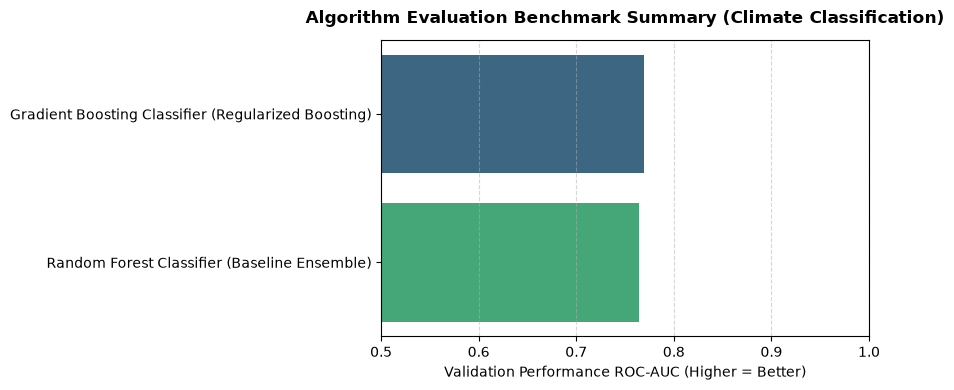

In [10]:
# CODE CELL 4: BENCHMARK PERFORMANCE PLOT
plt.figure(figsize=(9, 4))
sns.barplot(data=comparison_df, x='ROC-AUC Score', y='Model Name', palette='viridis', hue='Model Name', legend=False)
plt.xlim(0.5, 1.0)
plt.title('Algorithm Evaluation Benchmark Summary (Climate Classification)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Validation Performance ROC-AUC (Higher = Better)')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [11]:
# CODE CELL 5: CHOSEN PERFORMANCE DEPLOYMENT GENERATOR
best_model_name = comparison_df.iloc[0]['Model Name']
print(f"🏆 Champion architecture determined: {best_model_name}")

best_pipeline = trained_pipelines[best_model_name]

# Infer predictions over unseen competition feature fields
final_test_predictions = best_pipeline.predict(X_test_eng)

submission_df = pd.DataFrame({
    'ID': test_ids, 
    'is_climate_sensitive': final_test_predictions
})

submission_df.to_csv('climate_sensitivity_predictions_submission.csv', index=False)
print("🚀 Spreadsheet 'climate_sensitivity_predictions_submission.csv' generated cleanly for upload!")


🏆 Champion architecture determined: Gradient Boosting Classifier (Regularized Boosting)
🚀 Spreadsheet 'climate_sensitivity_predictions_submission.csv' generated cleanly for upload!


In [16]:
# Print the first 20 rows of your final predictions to verify them
print("\n--- Project 2 Predictions Sample ---")
print(pd.read_csv('climate_sensitivity_predictions_submission.csv').head(20))



--- Project 2 Predictions Sample ---
             ID  is_climate_sensitive
0   ID_E760D84B                     0
1   ID_6EDEA907                     1
2   ID_B9FFC8D8                     0
3   ID_74C6C94E                     0
4   ID_0E02825D                     1
5   ID_DA1C6468                     1
6   ID_82EBD610                     1
7   ID_791C412A                     1
8   ID_8FB9365C                     1
9   ID_724491A7                     0
10  ID_95C83AE3                     1
11  ID_6650ABA4                     1
12  ID_92412BFC                     1
13  ID_257F4327                     1
14  ID_CD7A50F0                     1
15  ID_8A80F1B6                     1
16  ID_90DB7797                     1
17  ID_4FF46045                     1
18  ID_33E6AFA0                     0
19  ID_FF308DAB                     0
